# RSW / 01 — Regime-switching AR(1) (discretized regime-switching OU) on MNQ 5-minute returns: discovery 2020-01 – 2023-06

Protocol: [`RSW 001`](../../discussions/MNQ_Regime_Switching/001_claude_rsw01_preregistration.md). Results in ticks per contract (1 tick = 0.25 points = $0.50).

z_t = c_s + φ_s z_{t−1} + σ_s ε_t with a hidden Markov state s. φ_s < 0 means reversal and φ_s > 0 continuation. M1/M2 have 2/3 states with constant transition probabilities. M3/M4 let the transition probabilities depend on the previous bar's order flow (volume surprise, |BVC imbalance|, imbalance × sign z, from the 1-minute bars). M0 is the one-state AR(1) benchmark.

- **R1**: out-of-sample predictive log score beats M0 (Holm ≤ 0.05).
- **R2**: φ_max − φ_min ≥ 0.05 with t ≥ 3 in every fit.
- **R3**: extreme states have p_stay ≥ 2/3 in every fit.
- **R4**: R²_OOS > 0 against zero and against M0, Clark–West against M0 (Holm ≤ 0.05).
- **E**: one-bar trade when the forecast move is ≥ 3 ticks; net > 0 (Holm ≤ 0.05), ≥ 150 trades, positive in ≥ 2 of 3 periods.

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
if SYNTHETIC:   # own folder: planted 2-state MS-AR(1), phi = -0.3 / +0.3, switching driven by volume surprise
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import regime_ar as R
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC = R.RSWConfig()
D = dt.date
OUT = Path("01"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
print("engines", R.RSW_VERSION, P.MRP_VERSION, V.REV_VERSION, "| synthetic" if SYNTHETIC else "| real data")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    NULL = os.environ.get("RSW_SYNTH_NULL") == "1"     # null smoke: no regimes, no flow effect (false-positive check)
    R.write_synthetic_regimes(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG,
                              **({"phis": (0.0, 0.0), "flow_effect": 0.0} if NULL else {}))

engines 0.1.0 0.1.1 0.2.0 | real data


In [2]:
if SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2020Q3": (D(2020, 7, 1), D(2020, 9, 30)), "2020Q4": (D(2020, 10, 1), D(2020, 12, 31))}
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
    PERIODS = {"2021": (D(2021, 1, 1), D(2021, 12, 31)), "2022": (D(2022, 1, 1), D(2022, 12, 31)),
               "2023H1": (D(2023, 1, 1), D(2023, 6, 30))}
NEED_PERIODS = int(np.ceil(2 / 3 * len(PERIODS)))
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
S = R.build_series(grid, sig2, m1, CFG, RC)
S = S[(S["trade_date"] >= CFG.train[0]) & (S["trade_date"] <= END)]
del m1
td = S["trade_date"].to_numpy()
OOS = td >= REFITS[0]
o = S["obs"].to_numpy()
print(f"{len(S):,} bars | observed {o.sum():,} | out-of-sample observed {(o & OOS).sum():,} | CME days {S['trade_date'].nunique()}")
cov = pd.DataFrame({
    "eligible": S["eligible"].mean(), "vsurp defined": np.isfinite(S["vsurp"]).mean(),
    "imb defined": np.isfinite(S["imb"]).mean(), "obs": o.mean(),
    "corr(imb, z)": np.corrcoef(S.loc[o, "imb"], S.loc[o, "z"])[0, 1],
    "corr(vsurp, |z|)": np.corrcoef(S.loc[o, "vsurp"], S.loc[o, "z"].abs())[0, 1],
    "lag-1 autocorr of z (obs, same day)": np.corrcoef(S.loc[o & S["has_lag"], "z"], S.loc[o & S["has_lag"], "zl"])[0, 1]},
    index=["value"]).T
display(cov.round(4))
zv = S[o].groupby(pd.to_datetime(S.loc[o, "trade_date"]).dt.to_period("Q"))["z"].var()
print("var(z) by quarter (1 = volatility model level right):"); display(zv.round(3).to_frame().T)

243,984 bars | observed 236,025 | out-of-sample observed 167,771 | CME days 884


,value
eligible,0.9677
vsurp defined,0.9873
imb defined,0.9874
obs,0.9674
"corr(imb, z)",0.8928
"corr(vsurp, |z|)",0.3363
"lag-1 autocorr of z (obs, same day)",-0.0048


var(z) by quarter (1 = volatility model level right):


trade_date,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2
z,1.043,1.021,1.032,1.022,1.035,1.036,1.055,1.033,1.039,1.055,1.071,1.103,1.063,1.052


## 1. Walk-forward fits (expanding, frozen per segment, causal filter)

In [3]:
MODELS = [("M0", 1, False)] + list(RC.models)
cache = OUT / f"fits_{R.RSW_VERSION}{'_synth' if SYNTHETIC else ''}.pkl"
if cache.exists():
    FC, FITS = pickle.load(open(cache, "rb"))
    print("loaded", cache)
else:
    FC, FITS = {}, {}
    for name, K, ex in MODELS:
        t0 = dt.datetime.now()
        FC[name], FITS[name] = R.walk_forward(S, CFG.train[0], REFITS, END, K, ex, RC)
        print(name, "K", K, "flow TVTP", ex, "| iterations", [f.n_iter for f in FITS[name]],
              "converged", [f.converged for f in FITS[name]], "|", dt.datetime.now() - t0)
    pickle.dump((FC, FITS), open(cache, "wb"))
fit_rows = []
for name, _, _ in MODELS:
    for a, f in zip(REFITS, FITS[name]):
        fit_rows.append({"model": name, "fit_before": a, "K": f.K, "loglik": f.loglik, "bic": f.bic,
                         "n_obs": f.n_obs, "iter": f.n_iter, "converged": f.converged})
fits_df = pd.DataFrame(fit_rows)
display(fits_df.round(1))

M0 K 1 flow TVTP False | iterations [3, 3, 3] converged [True, True, True] | 0:00:04.579571
M1 K 2 flow TVTP False | iterations [96, 82, 65] converged [True, True, True] | 0:01:16.682648
M2 K 3 flow TVTP False | iterations [331, 255, 103] converged [True, True, True] | 0:03:50.638679
M3 K 2 flow TVTP True | iterations [129, 106, 60] converged [True, True, True] | 0:05:59.577941
M4 K 3 flow TVTP True | iterations [345, 298, 233] converged [True, True, True] | 0:36:51.744463


,model,fit_before,K,loglik,bic,n_obs,iter,converged
0,M0,2021-01-01,1,-97834.2,195701.7,68254,3,True
1,M0,2022-01-01,1,-197684.5,395404.5,137667,3,True
2,M0,2023-01-01,1,-290286.7,580610.1,201433,3,True
3,M1,2021-01-01,2,-94866.4,189833.0,68254,96,True
4,M1,2022-01-01,2,-190712.6,381531.7,137667,82,True
5,M1,2023-01-01,2,-278551.4,557212.7,201433,65,True
6,M2,2021-01-01,3,-94582.5,189354.2,68254,331,True
7,M2,2022-01-01,3,-189968.2,380137.5,137667,255,True
8,M2,2023-01-01,3,-277237.2,554682.1,201433,103,True
9,M3,2021-01-01,2,-94800.3,189767.5,68254,129,True


In [4]:
for name, _, _ in MODELS:
    for a, f in zip(REFITS, FITS[name]):
        print(f"--- {name}, fit on data before {a}")
        display(f.table().round(4))

--- M0, fit on data before 2021-01-01


,c,phi,sd,se_phi,p_stay,exp_duration_bars
state,,,,,,
0,0.0098,-0.0055,1.0146,0.0038,1.0,1.000000e+12


--- M0, fit on data before 2022-01-01


,c,phi,sd,se_phi,p_stay,exp_duration_bars
state,,,,,,
0,0.0071,-0.0036,1.0172,0.0027,1.0,1.000000e+12


--- M0, fit on data before 2023-01-01


,c,phi,sd,se_phi,p_stay,exp_duration_bars
state,,,,,,
0,0.0039,-0.0031,1.0224,0.0022,1.0,1.000000e+12


... (20 outputs left out)

--- M4, fit on data before 2022-01-01


,c,phi,sd,se_phi,p_stay,exp_duration_bars,leave_logit_vsurp,leave_logit_abs_imb,leave_logit_imb_x_sign_z
state,,,,,,,,,
0,0.0547,-0.0692,0.6102,0.0031,0.8789,8.2567,0.1485,-0.1556,-0.1937
1,0.0109,-0.0188,1.0471,0.0035,0.8972,9.7245,-0.0013,0.4098,0.0134
2,-0.3962,0.2139,2.4295,0.0200,0.6568,2.9140,0.1743,-0.2788,0.7652


--- M4, fit on data before 2023-01-01


,c,phi,sd,se_phi,p_stay,exp_duration_bars,leave_logit_vsurp,leave_logit_abs_imb,leave_logit_imb_x_sign_z
state,,,,,,,,,
0,0.0486,-0.0671,0.6212,0.0024,0.8882,8.9452,0.1015,-0.3086,-0.1690
1,-0.0083,-0.0016,1.0861,0.0031,0.9085,10.9347,0.1168,0.5447,-0.0930
2,-0.3946,0.2021,2.9697,0.0228,0.6037,2.5232,0.1279,-0.2750,0.7732


## 2. Gates R1–R4

In [5]:
Sx = S[OOS]
day = Sx["trade_date"].to_numpy()
z_oos = np.where(Sx["obs"], Sx["z"], np.nan)
lp0 = FC["M0"]["lpz"].reindex(Sx.index).to_numpy()
fc0 = FC["M0"]["fc"].reindex(Sx.index).to_numpy()
rows = []
for name, K, ex in RC.models:
    f = FC[name].reindex(Sx.index)
    dm = R.predictive_dm(f["lpz"].to_numpy(), lp0, day, RC.nw_lags)
    gaps = [R.phi_gap(m) for m in FITS[name]]
    sc = R.forecast_scores(z_oos, f["fc"].to_numpy(), fc0, day, RC.nw_lags)
    rows.append({"model": name, "K": K, "flow_tvtp": ex,
                 "logscore_gain_per_bar": dm["per_bar_diff"], "R1_t": dm["t"], "R1_p": dm["p"],
                 "phi_min": [round(g["phi_min"], 3) for g in gaps], "phi_max": [round(g["phi_max"], 3) for g in gaps],
                 "t_gap_min": min(g["t_gap"] for g in gaps),
                 "R2": all(g["gap"] >= RC.phi_gap and g["t_gap"] >= RC.t_gap for g in gaps),
                 "stay_min": min(min(g["stay_min_state"], g["stay_max_state"]) for g in gaps),
                 "R3": all(min(g["stay_min_state"], g["stay_max_state"]) >= RC.min_stay for g in gaps),
                 "r2_vs_zero": sc["r2_oos_vs_zero"], "r2_vs_M0": sc["r2_oos_vs_M0"], "CW_t": sc["cw_t"],
                 "CW_p": sc["cw_p"], "hit_rate": sc["hit_rate"]})
G = pd.DataFrame(rows).set_index("model")
G["R1_p_holm"] = pd.Series(R.holm(G["R1_p"].to_dict()))
G["R1"] = (G["logscore_gain_per_bar"] > 0) & (G["R1_p_holm"] <= RC.alpha)
G["CW_p_holm"] = pd.Series(R.holm(G["CW_p"].to_dict()))
G["R4"] = (G["r2_vs_zero"] > 0) & (G["r2_vs_M0"] > 0) & (G["CW_p_holm"] <= RC.alpha)
m0s = R.forecast_scores(z_oos, fc0, np.zeros_like(fc0), day)
print(f"M0 (plain AR(1)): R2_OOS vs zero {m0s['r2_oos_vs_zero']:.5f}, phi per fit",
      [round(float(m.phi[0]), 4) for m in FITS["M0"]])
display(G.T)

M0 (plain AR(1)): R2_OOS vs zero -0.00001, phi per fit [-0.0055, -0.0036, -0.0031]


model,M1,M2,M3,M4
K,2,3,2,3
flow_tvtp,False,False,True,True
logscore_gain_per_bar,0.062904,0.070759,0.06349,0.073278
R1_t,15.479251,15.225422,15.83886,15.239343
R1_p,0.0,0.0,0.0,0.0
phi_min,"[-0.058, -0.053, -0.042]","[-0.073, -0.068, -0.062]","[-0.058, -0.054, -0.042]","[-0.071, -0.069, -0.067]"
phi_max,"[0.173, 0.124, 0.134]","[0.281, 0.214, 0.19]","[0.165, 0.125, 0.138]","[0.285, 0.214, 0.202]"
t_gap_min,14.563229,15.160128,14.629221,11.74115
R2,True,True,True,True
stay_min,0.398917,0.296356,0.704705,0.603671


## 3. Gate E: one-bar trade in the sign of the forecast (ticks per contract)

In [6]:
erows, TR = [], {}
for name, _, _ in RC.models:
    fc = FC[name]["fc"].reindex(Sx.index).to_numpy()
    for thr, cost, lab in ((RC.cost_ticks, RC.cost_ticks, "gate: thr 3, cost 3"),
                           (RC.realized_cost_ticks, RC.realized_cost_ticks, "thr 1.6, cost 1.6"),
                           (0.0, 0.0, "every bar, gross")):
        tr = R.one_bar_trades(Sx, fc, thr)
        TR[(name, lab)] = tr
        erows.append({"model": name, "rule": lab, **R.trade_stats(tr, cost, PERIODS)})
E = pd.DataFrame(erows).set_index(["model", "rule"])
gate = E.xs("gate: thr 3, cost 3", level="rule").copy()
gate["p_holm"] = pd.Series(R.holm(gate["p"].fillna(1.0).to_dict()))
gate["periods_pos"] = sum((gate[f"net_{p}"] > 0).astype(int) for p in PERIODS)
gate["E"] = (gate["trades"] >= RC.min_trades) & (gate["net"] > 0) & (gate["p_holm"] <= RC.alpha) & \
    (gate["periods_pos"] >= NEED_PERIODS)
display(E.round(3))
display(gate[["trades", "gross", "net", "t", "p_holm", "periods_pos", "E"]].round(3))

trades  gross    net      t      p  win_rate  trades_per_day  net_usd_total_1c  net_2021  net_2022  net_2023H1
model rule                                                                                                                               
M1    gate: thr 3, cost 3    8534  1.839 -1.161 -1.049  0.853     0.480          14.391           -4952.0    -1.559    -0.901      -1.860
      thr 1.6, cost 1.6     26211  1.216 -0.384 -0.823  0.795     0.497          42.550           -5026.8    -1.259     0.139      -0.817
      every bar, gross     167771  0.325  0.325  2.848  0.002     0.501         270.163           27287.5     0.070     0.552       0.418
M2    gate: thr 3, cost 3    6676  0.658 -2.342 -1.834  0.967     0.475          11.631           -7818.0    -3.903    -1.340      -4.684
      thr 1.6, cost 1.6     23270  1.080 -0.520 -1.129  0.871     0.492          37.837           -6045.0    -0.838    -0.539       0.946
      every bar, gross     167771  0.324  0.324  2.921  0.002     0.501         270.163           27150.5     0.270     0.418       0.257
M3    gate: thr 3, cost 3    7574  0.861 -2.139 -1.820  0.966     0.473          12.837           -8100.5    -2.842    -1.807      -2.330
      thr 1.6, cost 1.6     23683  0.801 -0.799 -1.582  0.943     0.494          38.198           -9460.9    -1.606    -0.566       0.330
      every bar, gross     167771  0.318  0.318  2.707  0.003     0.501         270.163           26660.5    -0.077     0.661       0.479
M4    gate: thr 3, cost 3    6932  0.843 -2.157 -1.784  0.963     0.474          11.729           -7475.5    -4.338    -0.814      -5.271
      thr 1.6, cost 1.6     22803  0.799 -0.801 -1.610  0.946     0.492          36.958           -9137.4    -0.873    -0.754      -0.864
      every bar, gross     167771  0.341  0.341  2.983  0.001     0.501         270.163           28639.5     0.143     0.529       0.394

,trades,gross,net,t,p_holm,periods_pos,E
model,,,,,,,
M1,8534,1.839,-1.161,-1.049,1.0,0,False
M2,6676,0.658,-2.342,-1.834,1.0,0,False
M3,7574,0.861,-2.139,-1.820,1.0,0,False
M4,6932,0.843,-2.157,-1.784,1.0,0,False


## 4. Descriptive: what the regimes are (filtered argmax state, out of sample)

In [7]:
for name, K, ex in RC.models:
    f = FC[name].reindex(Sx.index)
    P_ = f[[f"p{k}" for k in range(K)]].to_numpy()
    ok = Sx["obs"].to_numpy() & np.isfinite(P_).all(1)
    st = P_[ok].argmax(1)
    sx = Sx[ok]
    q = pd.qcut(np.sqrt(sx["sig2"]), 5, labels=[f"Q{i}" for i in range(1, 6)])
    print(f"=== {name}: share of bars in each state (states ordered by phi: 0 = most reverting)")
    tab = pd.concat({"all": pd.Series(st).value_counts(normalize=True).sort_index(),
                     **{s_: pd.Series(st[sx["session"].to_numpy() == s_]).value_counts(normalize=True).sort_index()
                        for s_ in P.SESSIONS},
                     **{str(y): pd.Series(st[pd.to_datetime(sx["trade_date"]).dt.year.to_numpy() == y]).value_counts(normalize=True).sort_index()
                        for y in sorted(pd.to_datetime(sx["trade_date"]).dt.year.unique())},
                     **{f"sigma {c}": pd.Series(st[(q == c).to_numpy()]).value_counts(normalize=True).sort_index()
                        for c in q.cat.categories}}, axis=1).fillna(0)
    display(tab.round(3))
    # realized lag-1 autocorrelation of z inside each filtered state: does the state label mean what phi says?
    hl = sx["has_lag"].to_numpy()
    ac = {k: np.corrcoef(sx["z"].to_numpy()[hl & (st == k)], sx["zl"].to_numpy()[hl & (st == k)])[0, 1]
          for k in range(K) if (hl & (st == k)).sum() > 100}
    print("out-of-sample lag-1 autocorr of z by filtered state:", {k: round(v, 4) for k, v in ac.items()})
    sm = R.smooth(S, FITS[name][-1])[OOS][ok].argmax(1)
    print(f"filtered vs smoothed state agreement (last fit): {np.mean(sm == st):.3f}")

=== M1: share of bars in each state (states ordered by phi: 0 = most reverting)


,all,asia,london,ny,post,2021,2022,2023,sigma Q1,sigma Q2,sigma Q3,sigma Q4,sigma Q5
0,0.959,0.968,0.95,0.957,0.954,0.958,0.957,0.967,0.96,0.959,0.958,0.954,0.964
1,0.041,0.032,0.05,0.043,0.046,0.042,0.043,0.033,0.04,0.041,0.042,0.046,0.036


out-of-sample lag-1 autocorr of z by filtered state: {0: np.float64(-0.0615), 1: np.float64(0.1632)}
filtered vs smoothed state agreement (last fit): 0.987
=== M2: share of bars in each state (states ordered by phi: 0 = most reverting)


,all,asia,london,ny,post,2021,2022,2023,sigma Q1,sigma Q2,sigma Q3,sigma Q4,sigma Q5
0,0.451,0.620,0.355,0.305,0.547,0.545,0.423,0.316,0.613,0.510,0.441,0.372,0.321
1,0.526,0.357,0.620,0.678,0.420,0.428,0.555,0.670,0.358,0.465,0.536,0.606,0.665
2,0.023,0.023,0.025,0.018,0.033,0.027,0.022,0.014,0.029,0.024,0.024,0.023,0.014


out-of-sample lag-1 autocorr of z by filtered state: {0: np.float64(-0.0976), 1: np.float64(-0.0238), 2: np.float64(0.1935)}
filtered vs smoothed state agreement (last fit): 0.795
=== M3: share of bars in each state (states ordered by phi: 0 = most reverting)


,all,asia,london,ny,post,2021,2022,2023,sigma Q1,sigma Q2,sigma Q3,sigma Q4,sigma Q5
0,0.951,0.965,0.942,0.946,0.934,0.95,0.947,0.962,0.956,0.953,0.95,0.945,0.952
1,0.049,0.035,0.058,0.054,0.066,0.05,0.053,0.038,0.044,0.047,0.05,0.055,0.048


out-of-sample lag-1 autocorr of z by filtered state: {0: np.float64(-0.0638), 1: np.float64(0.157)}
filtered vs smoothed state agreement (last fit): 0.975
=== M4: share of bars in each state (states ordered by phi: 0 = most reverting)


,all,asia,london,ny,post,2021,2022,2023,sigma Q1,sigma Q2,sigma Q3,sigma Q4,sigma Q5
0,0.355,0.506,0.269,0.229,0.396,0.325,0.361,0.405,0.497,0.409,0.339,0.276,0.254
1,0.632,0.483,0.715,0.759,0.579,0.658,0.628,0.588,0.487,0.577,0.647,0.711,0.739
2,0.013,0.011,0.016,0.012,0.025,0.017,0.012,0.007,0.016,0.014,0.014,0.013,0.008


out-of-sample lag-1 autocorr of z by filtered state: {0: np.float64(-0.1297), 1: np.float64(-0.0194), 2: np.float64(0.1812)}
filtered vs smoothed state agreement (last fit): 0.764


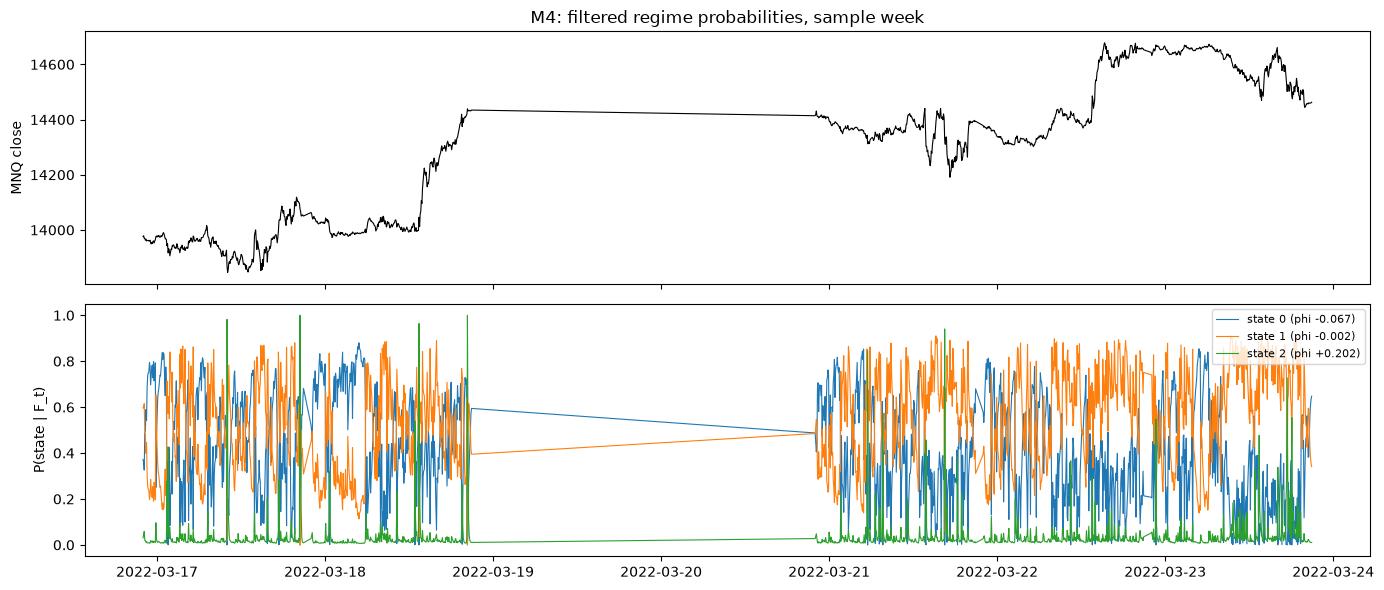

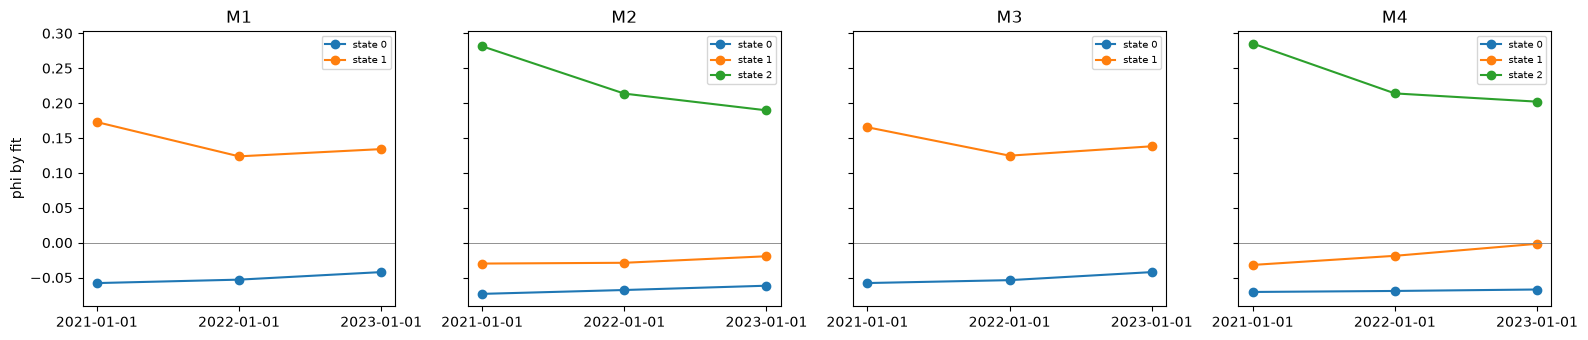

In [8]:
best = G["logscore_gain_per_bar"].idxmax()
K = dict((n, k) for n, k, _ in RC.models)[best]
f = FC[best].reindex(Sx.index)
days = sorted(Sx["trade_date"].unique())
week = [d for d in days if days[len(days) // 2] <= d < days[len(days) // 2] + dt.timedelta(days=7)]
sel = np.isin(Sx["trade_date"].to_numpy(), week)
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(Sx.index[sel], Sx["close"].to_numpy()[sel], lw=0.8, color="k"); ax[0].set_ylabel("MNQ close")
for k in range(K):
    ax[1].plot(Sx.index[sel], f[f"p{k}"].to_numpy()[sel], lw=0.8,
               label=f"state {k} (phi {FITS[best][-1].phi[k]:+.3f})")
ax[1].set_ylabel("P(state | F_t)"); ax[1].legend(loc="upper right", fontsize=8)
ax[0].set_title(f"{best}: filtered regime probabilities, sample week")
plt.tight_layout(); plt.savefig(OUT / "sample_week.png", dpi=110); plt.show()

fig, ax = plt.subplots(1, len(RC.models), figsize=(16, 3.5), sharey=True)
for i, (name, K, _) in enumerate(RC.models):
    for k in range(K):
        ax[i].plot([str(a) for a in REFITS], [m.phi[k] for m in FITS[name]], marker="o", label=f"state {k}")
    ax[i].axhline(0, color="grey", lw=0.6); ax[i].set_title(name); ax[i].legend(fontsize=7)
ax[0].set_ylabel("phi by fit")
plt.tight_layout(); plt.savefig(OUT / "phi_by_fit.png", dpi=110); plt.show()

## 5. Verdict

In [9]:
V_ = G[["R1", "R2", "R3", "R4"]].join(gate[["E"]])
V_["verdict"] = np.where(V_.all(axis=1), "CANDIDATE (2026 pre-registration)",
                np.where(V_[["R1", "R2", "R3"]].all(axis=1), "REGIMES_NO_TRADABLE_DIRECTION",
                np.where(V_["R1"], "R1_ONLY (volatility residue unless R2)", "NO_REGIME_STRUCTURE")))
display(V_)
summary = {"study": "RSW 01", "engine": R.RSW_VERSION, "synthetic": SYNTHETIC,
           "oos": [str(REFITS[0]), str(END)], "periods": {k: [str(a), str(b)] for k, (a, b) in PERIODS.items()},
           "coverage": {k: float(v) for k, v in cov["value"].items()},
           "fits": json.loads(fits_df.to_json(orient="records", date_format="iso")),
           "params": {n: [FITS[n][i].table().reset_index().to_dict(orient="records") for i in range(len(REFITS))]
                      for n, _, _ in MODELS},
           "gates_R": json.loads(G.drop(columns=["phi_min", "phi_max"]).to_json(orient="index")),
           "phi": {n: {"min": G.loc[n, "phi_min"], "max": G.loc[n, "phi_max"]} for n in G.index},
           "trades": json.loads(E.reset_index().to_json(orient="records")),
           "gate_E": json.loads(gate.to_json(orient="index")),
           "verdict": V_["verdict"].to_dict()}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

,R1,R2,R3,R4,E,verdict
model,,,,,,
M1,True,True,False,False,False,R1_ONLY (volatility residue unless R2)
M2,True,True,False,False,False,R1_ONLY (volatility residue unless R2)
M3,True,True,True,False,False,REGIMES_NO_TRADABLE_DIRECTION
M4,True,True,False,False,False,R1_ONLY (volatility residue unless R2)


written 01\summary.json
